In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("student_tea_snacks.csv")
df.head()

,student_id,gender,age_group,prefers_tea,tea_type,snack_choice,cups_per_day
0,S001,Male,21-23,No,Black,Samosa,2
1,S002,Male,21-23,No,Green,Samosa,3
2,S003,Male,18-20,No,Doodh Patti,Biscuit,0
3,S004,Male,21-23,Yes,NaN,Samosa,1
4,S005,Male,18-20,Yes,Green,Samosa,4


In [2]:
print(df.shape)
print(df.isna().sum())

(100, 7)
student_id       0
gender           0
age_group        0
prefers_tea      0
tea_type        23
snack_choice     0
cups_per_day     0
dtype: int64


In [3]:
tea_counts = df["tea_type"].value_counts()
print(tea_counts)
print("Most preferred:", tea_counts.idxmax())

tea_type
Green          29
Doodh Patti    25
Black          23
Name: count, dtype: int64
Most preferred: Green


In [4]:
df.groupby("gender")["cups_per_day"].mean().round(2)

gender
Female    2.6
Male      3.0
Name: cups_per_day, dtype: float64

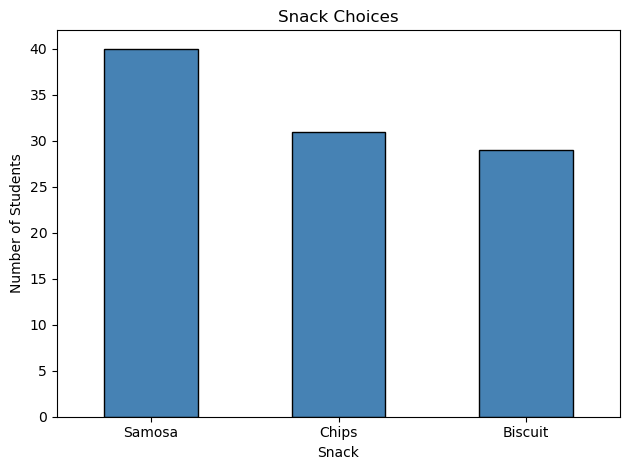

In [5]:
snack_counts = df["snack_choice"].value_counts()

snack_counts.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Snack Choices")
plt.xlabel("Snack")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
pd.crosstab(df["age_group"], df["tea_type"])

tea_type,Black,Doodh Patti,Green
age_group,,,
18-20,9,11,13
21-23,9,6,5
24-26,5,8,11


In [7]:
(pd.crosstab(df["age_group"], df["tea_type"], normalize="index") * 100).round(1)

tea_type,Black,Doodh Patti,Green
age_group,,,
18-20,27.3,33.3,39.4
21-23,45.0,30.0,25.0
24-26,20.8,33.3,45.8


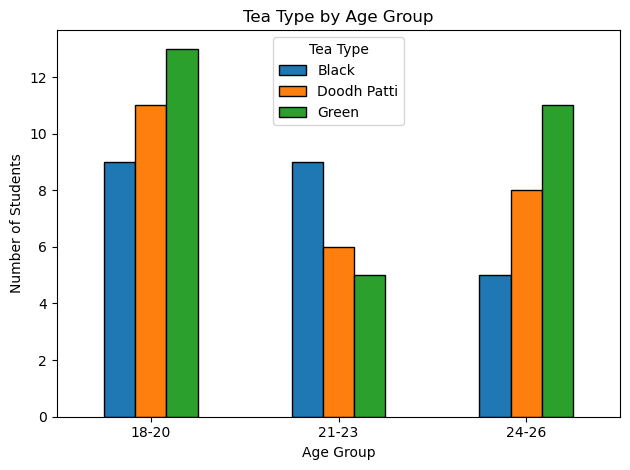

In [8]:
pd.crosstab(df["age_group"], df["tea_type"]).plot(kind="bar", edgecolor="black")
plt.title("Tea Type by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.legend(title="Tea Type")
plt.tight_layout()
plt.show()

In [9]:
no_tea = (df["prefers_tea"] == "No").sum()
print("Students who don't prefer tea:", no_tea)

Students who don't prefer tea: 49


In [10]:
print("Zero cups per day:", (df["cups_per_day"] == 0).sum())
print("Blank tea_type:", df["tea_type"].isna().sum())

Zero cups per day: 13
Blank tea_type: 23
